## A/B Testing, Randomized Controlled Trials

- We want to estimate the **average treatment effect**: The average difference in outcomes between the treatment and control groups
- Remember, the stakes are something like: If we implement this intervention at the scale of millions of patients, how many lives are:
    - Saved because the treatment works and our experiment showed it did (Good)
    - Not lost because the treatment doesn't work and our experiment showed it doesn't work (Good)
    - Not saved because the treatment works but our experiment failed to show it did (Bad)
    - Lost because the treatment actually harms patients, but our experiment falsely suggested it works (Very bad)

example from class
---
- getting a knee replacement and then coming back, does it work -> well people who need knee replacements typically do activities that harm knees, so they do it after replacement
    - also similar to the polio vaccine
- to fix this, we randomize assignments in 2 groups


In [1]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import pandas as pd

We generally can't compare what would have happened to observation $i$, if they had been assigned to the other treatment. This means we only observe
$$
y_{iA} = \text{Outcome for $i$ receiving treatment $A$ }
$$
or
$$
y_{iB} = \text{Outcome for $i$ receiving treatment $B$ }
$$
but not both. The **average outcome** for group $A$ is
$$
\frac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA}
$$
and the **average outcome** for group $B$ is
$$
\frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}.
$$
When we difference them, we get the **Average Treatment Effect (ATE)**:
$$
ATE = \dfrac{1}{\text{Size of group } A} \sum_{i \text{ receiving } A} y_{iA} \quad - \quad \frac{1}{\text{Size of group } B} \sum_{i \text{ receiving } B} y_{iB}
$$
As long as treatment is randomly assigned, there is no reason to think that the participants in group $A$ or $B$ are systematically different, and the **ATE** is an unbiased estimator of the true contrast in outcomes between groups $B$ and $A$. We "average away" the differences across the two groups to get an estimate of the difference in outcomes.

We then use bootstrapping to do two things:

1. Estimate the density/distribution for the averages outcomes in both groups
2. Estimate the ATE and its density/distribution

## Part 1

- First, we're going to evaluate a particular clinical trial, on chronic kidney disease:
    - ISCHEMIA-Chronic Kidney Disease Trial (ISCHEMIA-CKD)
    - ClinicalTrials.gov ID NCT01985360
    - Sponsor NYU Langone Health
    - Information provided by NYU Langone Health (Responsible Party)
- The study compared a "routine invasive therapy" (intra-aortic balloon pumps) intended to reduce death/heart attack versus more conservative medical interventions during heart surgery

<div>
<img src="./src/ischemia.png" width="700"/>
</div>

invasive = treatment, conservative = control

very similar amounts

**1.** Load the `./data/iabp.csv` data. Cross tabulate `Group` and `Survived`. What is the point estimate of the ATE? Would you rather get the intra aortic balloon pump or not? Remember, A means pump and B means not.

In [3]:
df = pd.read_csv('./data/iabp.csv')

## Crosstabs, average treatment effect:
print(pd.crosstab( df['Group'], df['Survived']), '\n')

ate = df.loc[ df['Group'] == 'Invasive', 'Survived'].mean() \
    - df.loc[ df['Group'] == 'Conservative', 'Survived'].mean() 
print('Estimated ATE: ', np.round(ate, 3))

Survived      0.0  1.0
Group                 
Conservative  290   99
Invasive      293   95 

Estimated ATE:  -0.01


Point estimate of ATE: -0.01
- The invasive group had a survival rate that is 1 percent lower than the conservative group.

I would not want to get the intra aortic balloon pump because the amount of people who survived and received the balloon pump is lower than than the amount of people who survived and did not receive the pump.

In [4]:
df.head(3)

,Survived,Group
0,1.0,Invasive
1,1.0,Invasive
2,1.0,Invasive


**2.** Bootstrap the average outcome for group A, the average outcome for group B, and difference then to get the ATE, 10,000 times. Store all of these estimates. This is very important: **Bootstrap the two groups separately, since this is a clinical trial and there was random assignment (we want to maintain the balance across treatment arms).

In [5]:
## Bootstrapping:
R = 10_000 # how many times we bootstrap

df_a = df.loc[ df['Group'] == 'Invasive',:]
df_b = df.loc[ df['Group'] == 'Conservative',:]

outcome_a = []
outcome_b = []
ate = [] # Store computed effects

for t in range(R):
    #df_t = df.sample( df.shape[0], axis=0, replace=True) # Resample

    df_at = df_a.sample(frac=1.0, replace=True) # sample
    df_bt = df_b.sample(frac=1.0, replace=True)

    oat = df_at['Survived'].mean() # Mean outcome for A
    obt = df_bt['Survived'].mean() # Mean outcome for B    
    ate_t = oat - obt # Compute ATE for this bootstrap sample

    outcome_a.append(oat) # Save new value
    outcome_b.append(obt) # Save new value
    ate.append(ate_t) # Save new value

**3.** Make a plot of the KDEs of the outcomes for the two groups, and a plot of the ECDFs for the two groups. What relationships do you see between the two groups?

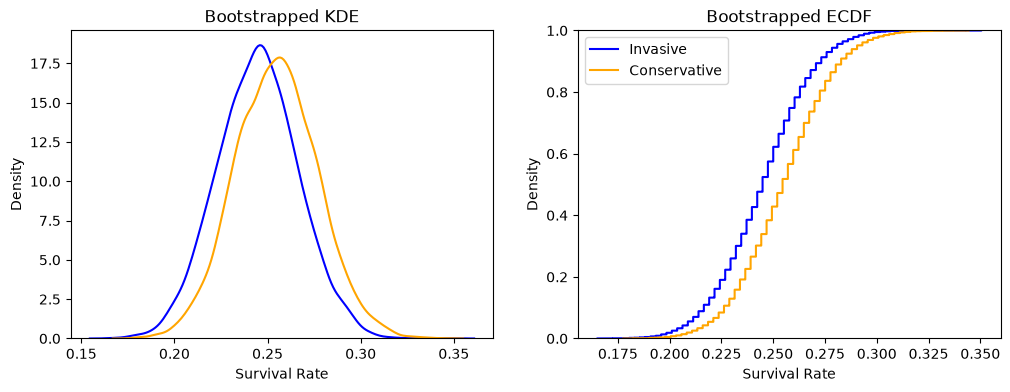

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_a, label='Invasive', color='blue', ax=ax[0])
sns.kdeplot(outcome_b, label='Conservative', color='orange', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Survival Rate', ylabel='Density')

sns.ecdfplot(outcome_a, label='Invasive', color='blue', ax=ax[1])
sns.ecdfplot(outcome_b, label='Conservative', color='orange', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Survival Rate', ylabel='Density')

plt.legend()
plt.show()

For the KDE, both the invasive and conservative plots have a similar shape. The conservative plot has a slightly higher survival rate, but they are relatively the same because there are no big differences.

For the ECDF, both the invasive and conservative plots are similar in shape. Once again, the conservative group tends to survive longer overally, but not by a huge margin.

from class interpretation
- there are not large differences in outcomes for the 2 groups, but it is hard to tell

**4.** Make a plot of the KDE and ECDF for the ATE. 

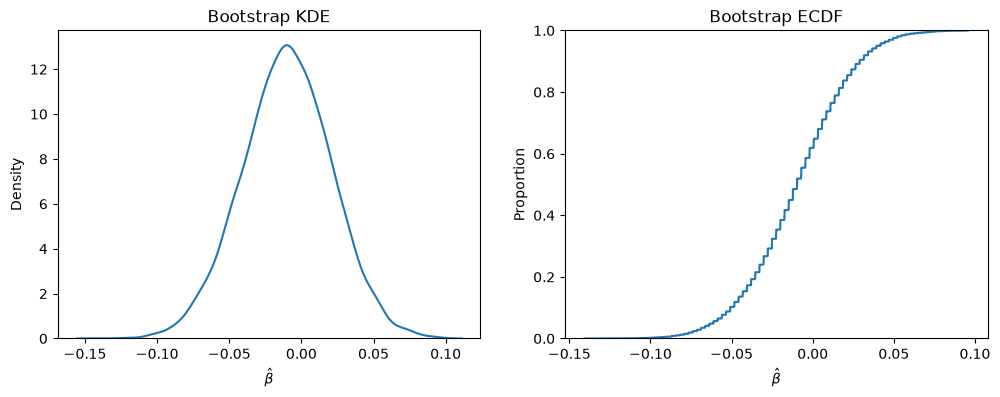

In [7]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])
ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")

## ECDF
sns.ecdfplot(ate, ax=ax[1])
ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")

plt.show()


Does it work? 0 is very close to the point estimate, it is in the CI with lots of neg and pos, so it doesnt work

**5.** Compute 90%, 95%, and 99% confidence intervals for the ATE. Is zero in those intervals? For which do we "fail to reject the null hypothesis that the effect size is zero" and for which do we "reject the null hypothesis that the effect size is zero"?

In [8]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

90% CI: [-0.06116662  0.03931605]
95% CI: [-0.07143614  0.04959187]
99% CI: [-0.0919687   0.07266852]


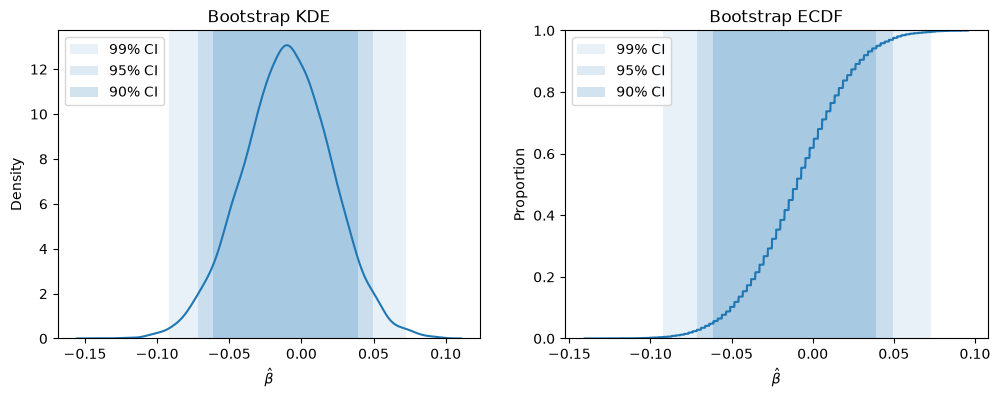

In [9]:
# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

90% CI: [-0.06116662  0.03931605]

95% CI: [-0.07143614  0.04959187]

99% CI: [-0.0919687   0.07266852]

For the 90%, 95%, and 99% confidence interval, zero is in the interval. Because the 0 is in the confidence interval, we fail to reject the null hypothesis that the effect size is zero. 

See here that the impact is 0, it might even be a little negative
we fail to reject the Ho, 

**6.** What have we learned about inserting balloons into hearts?

Based off the cross tab, the bootstrapping, and the confidence intervals, there is evidence of inserting balloons into hearts failing to improve the survival rate of a person.  

# Part 2

In `./data/diabetes.csv`, there is data from a clinical trial considering three treatments for pre-diabetics to reduce the progression to full diabetes: metformin, rosiglitazone, and lifestyle adjustments (diet, exercise). Unlike Part 1, there aren't two treatment arms (i.e. A = aortic balloon, B = no aortic balloon), but three (met, rosi, lifestyle).

You are a data analyst working for `clinicaltrials.gov` and the FDA to provide an unbiased review of the trial's results. The researchers have provided you with `./data/diabests.csv`.

In an ipynb or py file:

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 
2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 
3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.
4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.
5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

Then:

6. Write a short report (3-5 paragraphs) that summarizes the evidence from the trial for adopting each of the interventions or not. Use tables and visualizations. Write in a professional tone for a technical audience, and focus on evidence (or the lack thereof). Do not assume anyone has read your work in your notebooks.

Notes from class
---
- look at diabetes, 3 possibilities needed to compare 
- replicate the above
- in report, use graph images, and treat as if it is a professional project

Part 1
---

1. Load the `./data/diabetes.csv` data. Cross tabulate the outcomes for the three groups. What are the average outcomes for the three groups? 

In [10]:
data = pd.read_csv('./data/diabetes.csv')
data.head(5)

,Unnamed: 0,treatment,outcome
0,1,met,success
1,2,rosi,failure
2,3,rosi,success
3,4,lifestyle,success
4,5,met,success


In [ ]:
## Crosstabs, average treatment effect:
print(pd.crosstab( data['treatment'], data['outcome']), '\n')

outcome    failure  success
treatment                  
lifestyle      109      125
met            120      112
rosi            90      143 



In [18]:
df = data.copy()
df['outcome'] = df['outcome'].replace({ 'success': 1, 'failure': 0})
df

,Unnamed: 0,treatment,outcome
0,1,met,1
1,2,rosi,0
2,3,rosi,1
3,4,lifestyle,1
4,5,met,1
...,...,...,...
694,695,lifestyle,0
695,696,lifestyle,1
696,697,lifestyle,1
697,698,met,1


In [22]:
avg_met = df.loc[df['treatment']=='met', 'outcome'].mean()
avg_rosi = df.loc[df['treatment']=='rosi', 'outcome'].mean()
avg_lifestyle = df.loc[df['treatment']=='lifestyle', 'outcome'].mean()

print('met average: ', avg_met)
print('rosi average: ', avg_rosi)
print('lifestyle average: ', avg_lifestyle)

met average:  0.4827586206896552
rosi average:  0.6137339055793991
lifestyle average:  0.5341880341880342


Part 2
---

2. Bootstrap the outcomes for the three groups 10,000 times. Store all of these estimates. As this is another randomized controlled trial, do the resampling within the arms. 

In [28]:
## Bootstrapping:
R = 10_000 # how many times we bootstrap

df_met = df.loc[ df['treatment'] == 'met',:]
df_rosi = df.loc[ df['treatment'] == 'rosi',:]
df_lifestyle = df.loc[ df['treatment'] == 'lifestyle',:]


outcome_met = []
outcome_rosi = []
outcome_lifestyle= []

ate_m_r = []
ate_m_l = []
ate_r_l = []


for t in range(R):
    df_met_t = df_met.sample(frac=1.0, replace=True) 
    df_rosi_t = df_rosi.sample(frac=1.0, replace=True)
    df_lifestyle_t = df_lifestyle.sample(frac=1.0, replace=True)

    o_met_t = df_met_t['outcome'].mean() 
    o_rosi_t = df_rosi_t['outcome'].mean() 
    o_lifestyle_t = df_lifestyle_t['outcome'].mean()    

    oat_m_r = o_met_t - o_rosi_t
    oat_m_l = o_met_t - o_lifestyle_t
    oat_r_l = o_rosi_t - o_lifestyle_t
   

    outcome_met.append(o_met_t) 
    outcome_rosi.append(o_rosi_t) 
    outcome_lifestyle.append(o_lifestyle_t) 

    ate_m_r.append(oat_m_r)
    ate_m_l.append(oat_m_l)
    ate_r_l.append(oat_r_l)



Part 3
---

3. Plot the three densities on one plot and three distributions on another. Describe any patterns you see.

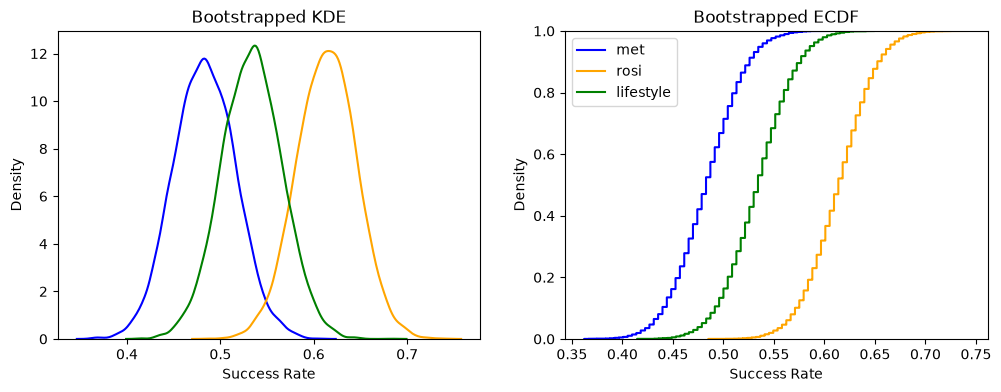

In [25]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(outcome_met, label='met', color='blue', ax=ax[0])
sns.kdeplot(outcome_rosi, label='rosi', color='orange', ax=ax[0])
sns.kdeplot(outcome_lifestyle, label='lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel='Success Rate', ylabel='Density')

sns.ecdfplot(outcome_met, label='met', color='blue', ax=ax[1])
sns.ecdfplot(outcome_rosi, label='rosi', color='orange', ax=ax[1])
sns.ecdfplot(outcome_lifestyle, label='lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel='Success Rate', ylabel='Density')

plt.legend()
plt.show()

For the KDE, all three treatments have the same shape. The rosi treatement has the highest success rate at its most dense point, followed by the lifestyle treatment, and lastly the met treatments.

Similarly for the ECDF, the patients treated with the rosi treatment tend to have a higer success rate, followed by lifestyle, and then the met treatment. All the ECDF plots appear to have similar shapes as well.

Part 4
---

4. There are three treatment effects: met versus rosi, met versus lifestyle, rosi versus lifestyle. Make KDE and ECDF plots of all these comparisons.

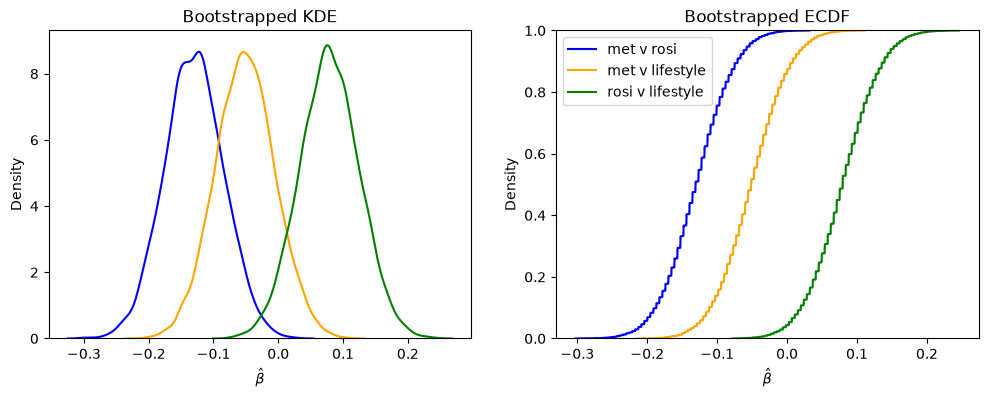

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))

sns.kdeplot(ate_m_r, label='met v rosi', color='blue', ax=ax[0])
sns.kdeplot(ate_m_l, label='met v lifestyle', color='orange', ax=ax[0])
sns.kdeplot(ate_r_l, label='rosi v lifestyle', color='green', ax=ax[0]).set(title='Bootstrapped KDE', xlabel=r"$\hat{\beta}$", ylabel='Density')

sns.ecdfplot(ate_m_r, label='met v rosi', color='blue', ax=ax[1])
sns.ecdfplot(ate_m_l, label='met v lifestyle', color='orange', ax=ax[1])
sns.ecdfplot(ate_r_l, label='rosi v lifestyle', color='green', ax=ax[1]).set(title='Bootstrapped ECDF', xlabel=r"$\hat{\beta}$", ylabel='Density')

plt.legend()
plt.show()

Part 5
---

5. Compute confidence intervals for each pairwise ATE based on its ECDF (percentile bootstrap). Do you find any statistically significant differences between the interventions? Which seems the most effective?

In [ ]:
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

print(f"90% CI: {ci90}")
print(f"95% CI: {ci95}")
print(f"99% CI: {ci99}")

# Percentile bootstrap confidence intervals
ci90 = np.quantile(ate, [.05, .95])
ci95 = np.quantile(ate, [.025, .975])
ci99 = np.quantile(ate, [.005, .995])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))

## KDE
sns.kdeplot(ate, ax=ax[0])

ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[0].set_xlabel(r"$\hat{\beta}$")
ax[0].set_title("Bootstrap KDE")
ax[0].legend()

## ECDF
sns.ecdfplot(ate, ax=ax[1])

ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

ax[1].set_xlabel(r"$\hat{\beta}$")
ax[1].set_title("Bootstrap ECDF")
ax[1].legend()

In [31]:
def get_quantiles_plot(ate):
    ci90 = np.quantile(ate, [.05, .95])
    ci95 = np.quantile(ate, [.025, .975])
    ci99 = np.quantile(ate, [.005, .995])

    fig, ax = plt.subplots(1, 2, figsize=(12, 4))

    ## KDE
    sns.kdeplot(ate, ax=ax[0])

    ax[0].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[0].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[0].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    ax[0].set_xlabel(r"$\hat{\beta}$")
    ax[0].set_title("Bootstrap KDE")
    ax[0].legend()

    ## ECDF
    sns.ecdfplot(ate, ax=ax[1])

    ax[1].axvspan(ci99[0], ci99[1], alpha=0.10, label="99% CI")
    ax[1].axvspan(ci95[0], ci95[1], alpha=0.15, label="95% CI")
    ax[1].axvspan(ci90[0], ci90[1], alpha=0.20, label="90% CI")

    ax[1].set_xlabel(r"$\hat{\beta}$")
    ax[1].set_title("Bootstrap ECDF")
    ax[1].legend()

    return ci90, ci95, ci99

ATE met and rosi at CI90:  [-0.20412165 -0.05362957]
ATE met and rosi at CI95:  [-0.21707165 -0.04064257]
ATE met and rosi at CI99:  [-0.2471142  -0.01474397]


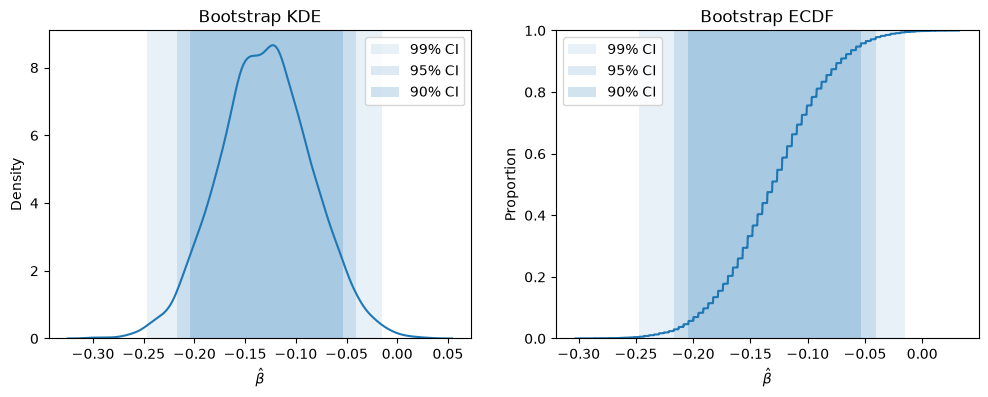

In [33]:
ci90_mr, ci95_mr, ci99_mr = get_quantiles_plot(ate_m_r)
print('ATE met and rosi at CI90: ', ci90_mr)
print('ATE met and rosi at CI95: ', ci95_mr)
print('ATE met and rosi at CI99: ', ci99_mr)

ATE met and lifestyle at CI90:  [-0.12466844  0.02578839]
ATE met and lifestyle at CI95:  [-0.14157825  0.03879402]
ATE met and lifestyle at CI99:  [-0.16757018  0.06474801]


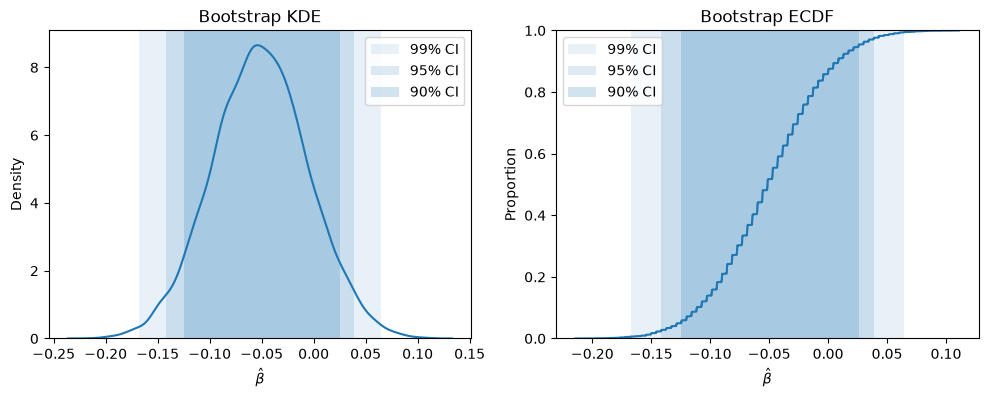

In [34]:
ci90_ml, ci95_ml, ci99_ml = get_quantiles_plot(ate_m_l)
print('ATE met and lifestyle at CI90: ', ci90_ml)
print('ATE met and lifestyle at CI95: ', ci95_ml)
print('ATE met and lifestyle at CI99: ', ci99_ml)

ATE rosi and lifestyle at CI90:  [0.00251275 0.15646895]
ATE rosi and lifestyle at CI95:  [-0.0104545   0.16947287]
ATE rosi and lifestyle at CI99:  [-0.04035068  0.19942409]


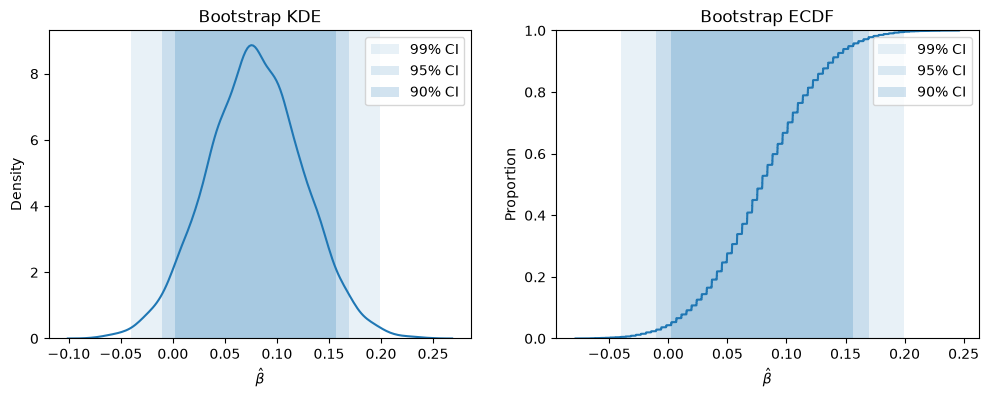

In [35]:
ci90_rl, ci95_rl, ci99_rl = get_quantiles_plot(ate_r_l)
print('ATE rosi and lifestyle at CI90: ', ci90_rl)
print('ATE rosi and lifestyle at CI95: ', ci95_rl)
print('ATE rosi and lifestyle at CI99: ', ci99_rl)

<b> Met v Rosi </b>  
ATE met and rosi at CI90:  [-0.20412165 -0.05362957]  
ATE met and rosi at CI95:  [-0.21707165 -0.04064257]  
ATE met and rosi at CI99:  [-0.2471142  -0.01474397]  
There is a statistically significant difference. The confidence intervals at 90%, 95%, and 99% all do not include 0, so we reject the null hypothesis that there is zero differences between the 2 treatments.  

<b> Met v Lifestyle </b>   
ATE met and lifestyle at CI90:  [-0.12466844  0.02578839]  
ATE met and lifestyle at CI95:  [-0.14157825  0.03879402]  
ATE met and lifestyle at CI99:  [-0.16757018  0.06474801]  
There is not a statistically significant difference between these 2 treatments. At the 90%, 95%, and 99% confidenct intervals, 0 is included. We fail to reject the null hypothesis that there are zero differences between the 2 treatments. 

<b> Rosi v Lifestyle </b>  
ATE rosi and lifestyle at CI90:  [0.00251275 0.15646895]  
ATE rosi and lifestyle at CI95:  [-0.0104545   0.16947287]  
ATE rosi and lifestyle at CI99:  [-0.04035068  0.19942409]  
Because the interal is all positive betas, at the 90% confidence interval, there is a statically significant difference between the 2 treatments. At the 95% and the 99& confidence intervals, there is not a statistically significant difference between the 2 treatments. Both intervals contain 0, so we fail to reject the null hypothesis. 

There is evidence based off the KDE plots, ECDF plots, and the pairwise ATEs that Rosi is the most effective. 